# Question 3.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

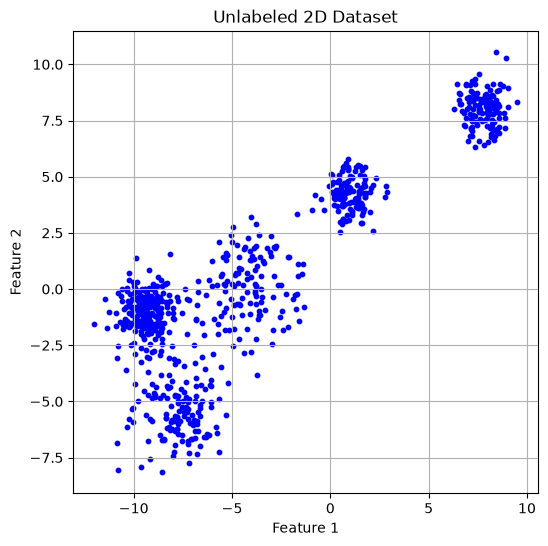

In [15]:
rng = np.random.RandomState(3)
k0 = rng.randint(4, 8)                      # hidden
stds = rng.uniform(0.6, 1.5, k0)            # hidden
X, _ = make_blobs(n_samples=800, centers=k0, cluster_std=stds,
                  center_box=(-10, 10), random_state=3)

plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=10, color='blue')
plt.title('Unlabeled 2D Dataset')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

In [16]:
k_values = range(2, 9)
sse, sil, models = [], [], {}
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    models[k] = km
    sse.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    print(f"k = {k}: SSE = {km.inertia_:9.1f}   silhouette = {sil[-1]:.3f}")

k = 2: SSE =   10323.1   silhouette = 0.685
k = 3: SSE =    5624.1   silhouette = 0.638
k = 4: SSE =    3443.8   silhouette = 0.606
k = 5: SSE =    1431.1   silhouette = 0.681
k = 6: SSE =    1247.4   silhouette = 0.639
k = 7: SSE =    1125.4   silhouette = 0.526
k = 8: SSE =    1008.0   silhouette = 0.587


## (a) Plot Within-cluster SSE  

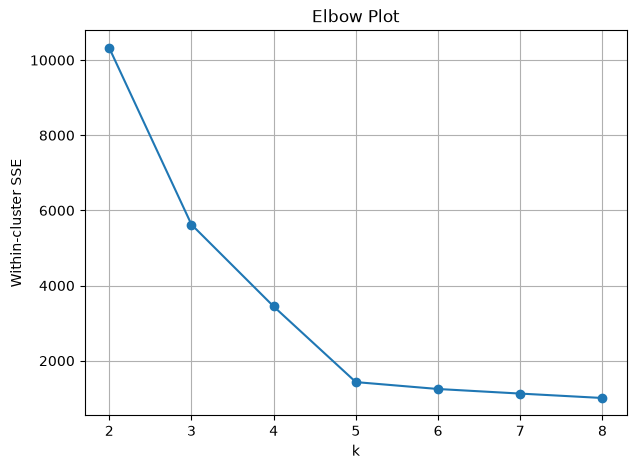

In [17]:
plt.figure(figsize=(7, 5))
plt.plot(k_values, sse, 'o-')
plt.xlabel('k')
plt.ylabel('Within-cluster SSE')
plt.title('Elbow Plot')
plt.grid(True)
plt.show()

##  (b) Plot Average silhouette vs k

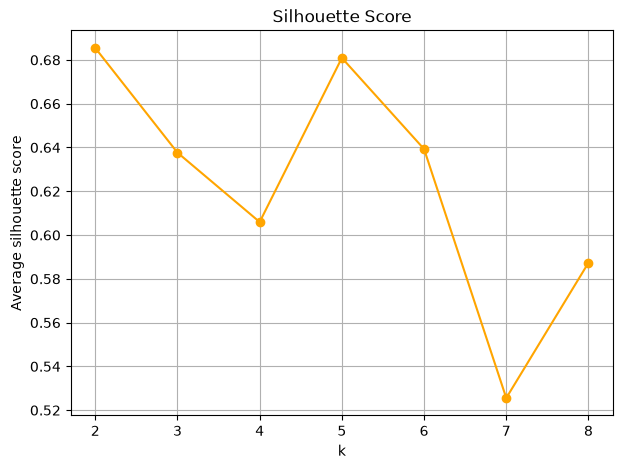

In [18]:
plt.figure(figsize=(7, 5))
plt.plot(k_values, sil, 'o-', color='orange')
plt.xlabel('k')
plt.ylabel('Average silhouette score')
plt.title('Silhouette Score')
plt.grid(True)
plt.show()

## (c) Choice of k

**Pick k = 5.** The plot for the within-cluster SSE as a function of k has a clear bend at k = 5 where SSE drops sharply up to k = 5 and after that each extra cluster lowers it slightly. The silhouette score has a strong local peak at k = 5 then drop for larger k. So k = 5 is the simplest model that captures all the visible structure.

## (d) Clustering for the chosen k

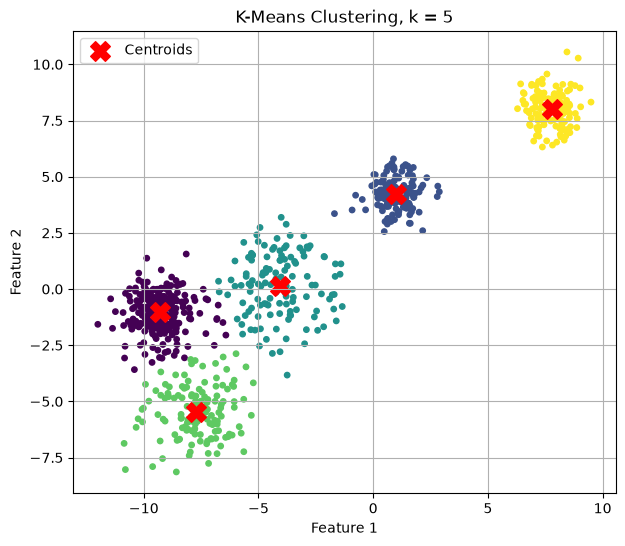

In [19]:
k_best = 5
km = models[k_best]

plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=km.labels_, cmap='viridis', s=15)
plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
            c='red', s=200, marker='X', label='Centroids')
plt.title(f'K-Means Clustering, k = {k_best}')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

## If the elbow plot and silhouette plot suggest different answers, briefly explain which one you trust morefor your dataset and why.

The silhouette score is highest at k = 2, but the elbow plot bends at k = 5. I trust the elbow plot more for this dataset. With k = 2, k-means only separates the far blob from everything else, so the silhouette is high just because those two groups are far apart, even though the big group clearly has more clusters inside it. Also, the silhouette at k = 5 is almost the same as at k = 2, so it still supports k = 5.